# Cellpose_FineTune — Cellpose 4 fine-tuned on curated red-channel crops
The generic `cpsam` model outlines only part of the somata on the stitched Olympus red channel (mCherry). This notebook
fine-tunes it on a few hand-curated 2D crops of that channel; Step 2 of `AnalyzeTCSPC_XYTZTile.ipynb` (`cp_model_path`)
and the tuning grid of `MultiDay_Reference.ipynb` (`model_path` in the settings) then use the result.

1. **Training crops** — square crops with the most cell-scale structure, spread over the volume(s); resized so the
   expected soma diameter is 30 px (the scale Cellpose segments at) + masks of the generic model as a starting point.
2. **Curation in napari** — correct the masks crop by crop (the slider is the crop index).
3. **Training** — a fraction of the curated crops is held out for testing.
4. **Evaluation** — generic vs fine-tuned on the held-out crops (average precision).
5. **Use** — model path + diameter for Step 2.

Models: `D:\Peredox_FLIM\cellpose_models\models\<name>` (+ `.json`), training data: `D:\Peredox_FLIM\cellpose_training\<name>\`.

In [1]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'   # prevent OpenMP conflict between MKL and torch on Windows
import torch   # must be imported before numpy/scipy to avoid OpenMP runtime clash

import sys
import json
import importlib
import subprocess
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile
from skimage.segmentation import find_boundaries

sys.path.insert(0, 'X:/FLIM_2026')
import multiday as md
importlib.reload(md)
print(f'torch {torch.__version__}  GPU available: {torch.cuda.is_available()}')

torch 2.5.1+cu121  GPU available: True


## 1. Training crops
`sources`: stitched volumes + voxel size (dz, dy, dx) µm — the Olympus red channel of a session (Step 0e,
`analysis/intensity_coverage/<base>_stitched_CH1.tif`). Crops can come from several sessions/subjects; more variety generalises better.
`diameter_um` sets the training scale: use the same value as `cp_diameter_um` in Step 2 (it is stored with the model).
Re-exporting (`rerun_export = True`) starts the curation over: existing curated masks are kept as `train_masks_old.tif`.

Reloaded 16 training crops <- D:\Peredox_FLIM\cellpose_training\cpsam_red_336
generic model: 4 cells per crop on average


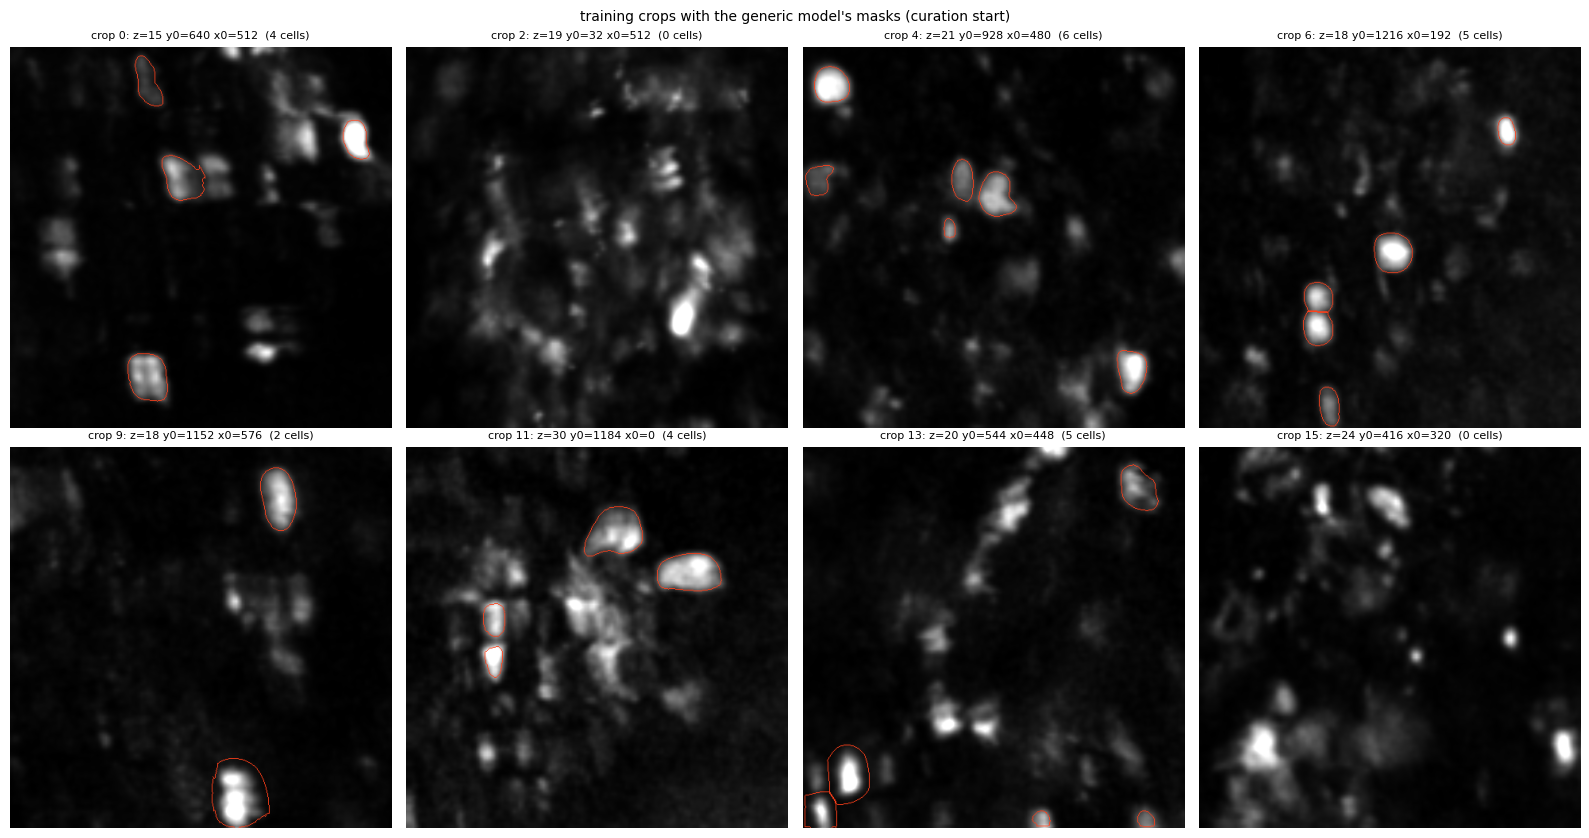

In [2]:
model_name     = 'cpsam_red_336'
train_root     = r'D:\Peredox_FLIM\cellpose_training'
models_root    = r'D:\Peredox_FLIM\cellpose_models'
sources = [   # (stitched volume, voxel size (dz, dy, dx) µm)
    (r'D:\Peredox_FLIM\XYZTTile1_336_X0.4Y-2.8_Decay128_512x512_Z210_Ch1_T1_P1_S1\analysis\intensity_coverage\XYZTTile1_336_X0.4Y-2.8_Decay128_512x512_Z210_Ch1_T1_P1_S1_stitched_CH1.tif',
     (4.0, 0.9944, 0.9944)),
]
n_crops        = 16      # per source volume
crop_um        = 128.0   # crop width (µm); 128 µm at d = 8 µm -> 480 x 480 px crops
diameter_um    = 8.0     # expected soma diameter (µm) -> 30 px in the crops
start_cellprob = 0.0     # cellprob_threshold of the generic model for the starting masks
rerun_export   = False

train_dir = os.path.join(train_root, model_name)
os.makedirs(train_dir, exist_ok=True)
F = dict(img=os.path.join(train_dir, 'train_img.tif'), auto=os.path.join(train_dir, 'train_masks_auto.tif'),
         masks=os.path.join(train_dir, 'train_masks.tif'), crops=os.path.join(train_dir, 'train_crops.json'))
_want = dict(sources=[[p, list(s)] for p, s in sources], n_crops=n_crops, crop_um=crop_um,
             diameter_um=diameter_um, start_cellprob=start_cellprob)
_old = json.load(open(F['crops'])) if os.path.exists(F['crops']) else None
if _old and _old['settings'] == _want and os.path.exists(F['img']) and os.path.exists(F['auto']) and not rerun_export:
    train_img, train_auto, crop_info = tifffile.imread(F['img']), tifffile.imread(F['auto']), _old['crops']
    print(f'Reloaded {len(train_img)} training crops <- {train_dir}')
else:
    if os.path.exists(F['masks']):
        if not rerun_export:
            raise RuntimeError('Curated masks exist for other crops/settings; set rerun_export = True to start over '
                               '(they are kept as train_masks_old.tif).')
        os.replace(F['masks'], F['masks'].replace('.tif', '_old.tif'))
    _imgs, _auto, crop_info = [], [], []
    for _p, _sp in sources:
        _vol, _sp = md.load_volume(_p, _sp)
        _crops, _cpx = md.training_crops(_vol, _sp, n=n_crops, crop_um=crop_um)
        _im, _mk, _scale = md.export_training_set(_vol, _sp, _crops, _cpx, diameter_um, cellprob_threshold=start_cellprob)
        _imgs.append(_im); _auto.append(_mk)
        crop_info += [dict(source=_p, z=int(z), y0=int(y0), x0=int(x0), crop_px=int(_cpx), scale=float(_scale))
                      for z, y0, x0 in _crops]
        print(f'{os.path.basename(_p)}: {len(_crops)} crops of {_cpx} px -> {_im.shape[1]} px')
    train_img, train_auto = np.concatenate(_imgs), np.concatenate(_auto)
    tifffile.imwrite(F['img'], train_img)
    tifffile.imwrite(F['auto'], train_auto, compression='zlib')
    with open(F['crops'], 'w') as _f:
        json.dump(dict(settings=_want, crops=crop_info), _f, indent=1)
    print(f'Saved {len(train_img)} crops -> {train_dir}')
print(f'generic model: {np.mean([len(np.unique(m)) - 1 for m in train_auto]):.0f} cells per crop on average')

_show = np.linspace(0, len(train_img) - 1, min(8, len(train_img))).round().astype(int)
fig, axs = plt.subplots(2, len(_show) // 2, figsize=(4.2 * len(_show) // 2, 8.6), squeeze=False)
for _a, i in zip(axs.ravel(), _show):
    _im = train_img[i]
    _im = np.clip((_im - np.percentile(_im, 1)) / (np.percentile(_im, 99.7) - np.percentile(_im, 1)), 0, 1)
    _rgb = np.dstack([_im] * 3)
    _rgb[find_boundaries(train_auto[i], mode='inner')] = (1.0, 0.25, 0.1)
    _a.imshow(_rgb); _a.axis('off')
    _c = crop_info[i]
    _a.set_title(f'crop {i}: z={_c["z"]} y0={_c["y0"]} x0={_c["x0"]}  ({len(np.unique(train_auto[i])) - 1} cells)', fontsize=8)
plt.suptitle('training crops with the generic model\'s masks (curation start)', fontsize=10)
plt.tight_layout(); plt.show()

## 2. Curation in napari
Opens the crops (slider = crop index) with the masks in napari (`napari-env`); the cell waits until the window is closed.
Start: `train_masks.tif` if it exists (continue curating), else the generic model's `train_masks_auto.tif`.
- **outline every soma in a crop** you curate: unlabelled cells are learned as background. Fewer complete crops are
  better than many partial ones; crops left empty (all masks deleted) are skipped in training
- select the **cells** layer: paint `P`, erase `E`, fill `F`, pick a label `L`; a new cell needs an unused label number
  (the layer starts at max + 1); delete a cell: fill it with 0; split/merge: repaint with a new / the other label
- **Ctrl+Shift+S** saves to `train_masks.tif`; closing the window saves too

In [3]:
napari_env = r'X:\conda\envs\napari-env'
_start = F['masks'] if os.path.exists(F['masks']) else F['auto']
_env = dict(os.environ)
_env['PATH'] = ';'.join([napari_env, rf'{napari_env}\Library\mingw-w64\bin', rf'{napari_env}\Library\usr\bin',
                         rf'{napari_env}\Library\bin', rf'{napari_env}\Scripts', rf'{napari_env}\bin', _env['PATH']])
_env.pop('KMP_DUPLICATE_LIB_OK', None)
print(f'napari: {os.path.basename(_start)} -> {os.path.basename(F["masks"])}   (close the window when done)')
_r = subprocess.run([rf'{napari_env}\python.exe', r'X:\FLIM_2026\napari_curate.py', F['img'], _start, F['masks'],
                     '1,1,1'], env=_env, capture_output=True, text=True)
print(_r.stdout[-2000:] or '(no output)')
if _r.returncode:
    print(_r.stderr[-3000:])

napari: train_masks_auto.tif -> train_masks.tif   (close the window when done)
saved 8 labels -> D:\Peredox_FLIM\cellpose_training\cpsam_red_336\train_masks.tif



## 3. Training
Fine-tunes `cpsam` on the curated crops (`train_masks.tif`); `test_frac` of them are held out. The model is retrained
only when the curated masks or the training settings change. Defaults follow the Cellpose 4 fine-tuning recipe
(Adam-W, learning rate 1e-5, weight decay 0.1); ~200 epochs on 10–20 crops take a few minutes on the GPU.

Training on 13 crops, testing on 3  (200 epochs)...


100%|██████████| 3/3 [00:00<00:00, 1493.70it/s]


Done in 767 s  ->  D:\Peredox_FLIM\cellpose_models\models\cpsam_red_336


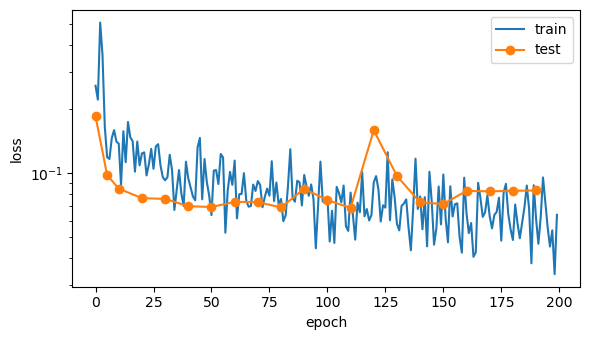

In [4]:
test_frac     = 0.2
n_epochs      = 200
learning_rate = 1e-5
weight_decay  = 0.1
batch_size    = 4
rerun_train   = False

if not os.path.exists(F['masks']):
    raise RuntimeError('No curated train_masks.tif yet: curate the crops first (section 2).')
train_masks = tifffile.imread(F['masks']).astype(np.uint16)
_curated = np.flatnonzero([m.max() > 0 for m in train_masks])
_rng = np.random.default_rng(0)
_perm = _rng.permutation(_curated)
_n_test = max(1, int(round(test_frac * _perm.size)))
test_idx, train_idx = np.sort(_perm[:_n_test]), np.sort(_perm[_n_test:])
model_path = os.path.join(models_root, 'models', model_name)
_tr_settings = dict(n_epochs=n_epochs, learning_rate=learning_rate, weight_decay=weight_decay, batch_size=batch_size,
                    train_idx=train_idx.tolist(), test_idx=test_idx.tolist(),
                    masks_mtime=os.path.getmtime(F['masks']))
_meta = json.load(open(model_path + '.json')) if os.path.exists(model_path + '.json') else None
if os.path.exists(model_path) and _meta and _meta['training'] == _tr_settings and not rerun_train:
    print(f'Reusing {model_path}  (trained {_meta["date"]})')
else:
    print(f'Training on {train_idx.size} crops, testing on {test_idx.size}  ({n_epochs} epochs)...', flush=True)
    _t0 = datetime.now()
    _res = md.finetune_cellpose(train_img[train_idx], train_masks[train_idx], train_img[test_idx],
                                train_masks[test_idx], models_root, model_name, n_epochs=n_epochs,
                                learning_rate=learning_rate, weight_decay=weight_decay, batch_size=batch_size)
    _meta = dict(model_path=_res['path'], diameter_um=diameter_um, crop_um=crop_um, base_model='cpsam',
                 sources=[p for p, _ in sources], training=_tr_settings, date=datetime.now().isoformat(timespec='minutes'),
                 train_loss=_res['train_loss'], test_loss=_res['test_loss'])
    with open(model_path + '.json', 'w') as _f:
        json.dump(_meta, _f, indent=1)
    print(f'Done in {(datetime.now() - _t0).total_seconds():.0f} s  ->  {model_path}')
_tl = np.array(_meta['test_loss'], float)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(_meta['train_loss'], label='train')
ax.plot(np.flatnonzero(_tl > 0), _tl[_tl > 0], 'o-', label='test')
ax.set_xlabel('epoch'); ax.set_ylabel('loss'); ax.set_yscale('log'); ax.legend()
plt.tight_layout(); plt.show()

## 4. Evaluation on the held-out crops
Average precision (AP) of the generic and the fine-tuned model against the curated masks at IoU 0.5 / 0.75
(1 = every cell found with no false positives). Montage rows: curated / generic / fine-tuned.

mean AP@0.5: generic 0.58  ->  fine-tuned 0.43   |   mean AP@0.75: 0.58 -> 0.27


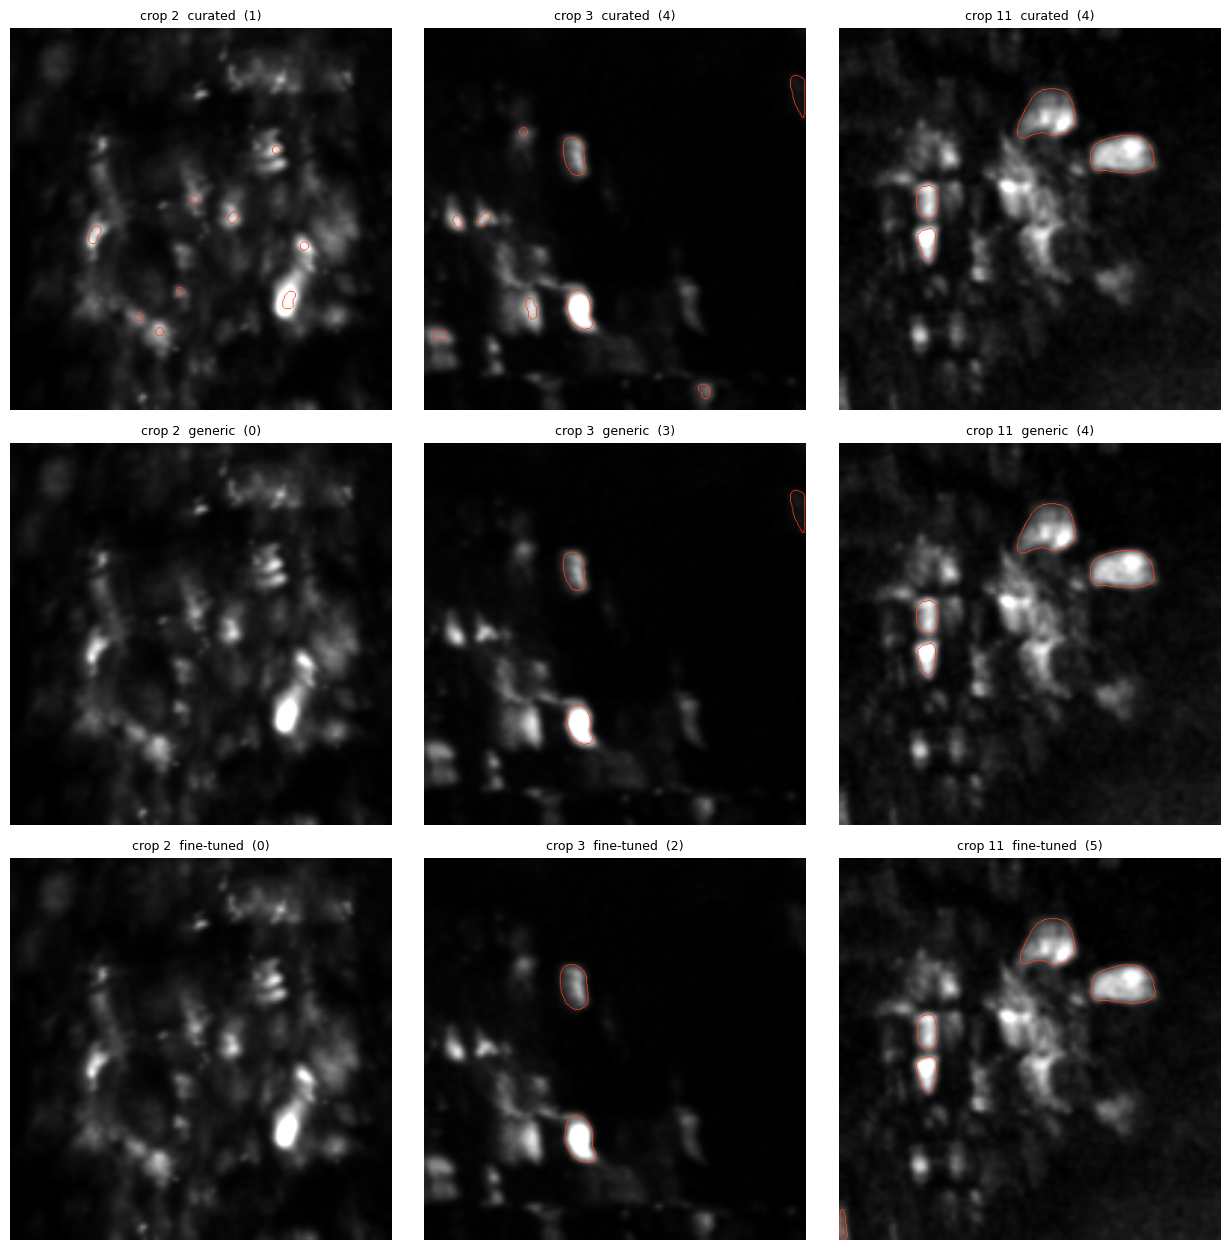

,crop,cells_curated,cells_generic,cells_finetuned,AP50_generic,AP50_finetuned,AP75_generic,AP75_finetuned
0,2,1,0,0,0.00,0.0,0.00,0.0
1,3,4,3,2,0.75,0.5,0.75,0.0
2,11,4,4,5,1.00,0.8,1.00,0.8


In [5]:
from cellpose import metrics
eval_cellprob = 0.0
_true = [train_masks[i] for i in test_idx]
_gen  = md.eval_crops(train_img[test_idx], None, cellprob_threshold=eval_cellprob)
_ft   = md.eval_crops(train_img[test_idx], model_path, cellprob_threshold=eval_cellprob)
_ap_g = metrics.average_precision(_true, _gen, threshold=[0.5, 0.75])[0]
_ap_f = metrics.average_precision(_true, _ft, threshold=[0.5, 0.75])[0]
df_eval = pd.DataFrame(dict(crop=test_idx, cells_curated=[len(np.unique(m)) - 1 for m in _true],
                            cells_generic=[len(np.unique(m)) - 1 for m in _gen],
                            cells_finetuned=[len(np.unique(m)) - 1 for m in _ft],
                            AP50_generic=_ap_g[:, 0].round(2), AP50_finetuned=_ap_f[:, 0].round(2),
                            AP75_generic=_ap_g[:, 1].round(2), AP75_finetuned=_ap_f[:, 1].round(2)))
print(f'mean AP@0.5: generic {_ap_g[:, 0].mean():.2f}  ->  fine-tuned {_ap_f[:, 0].mean():.2f}   |   '
      f'mean AP@0.75: {_ap_g[:, 1].mean():.2f} -> {_ap_f[:, 1].mean():.2f}')
fig, axs = plt.subplots(3, len(test_idx), figsize=(4.2 * len(test_idx), 12.6), squeeze=False)
for j, i in enumerate(test_idx):
    _im = train_img[i]
    _im = np.clip((_im - np.percentile(_im, 1)) / (np.percentile(_im, 99.7) - np.percentile(_im, 1)), 0, 1)
    for r, (_m, _nm) in enumerate([(_true[j], 'curated'), (_gen[j], 'generic'), (_ft[j], 'fine-tuned')]):
        _rgb = np.dstack([_im] * 3)
        _rgb[find_boundaries(_m, mode='inner')] = (1.0, 0.25, 0.1)
        axs[r, j].imshow(_rgb); axs[r, j].axis('off')
        axs[r, j].set_title(f'crop {i}  {_nm}  ({len(np.unique(_m)) - 1})', fontsize=9)
plt.tight_layout(); plt.show()
df_eval

## 5. Use the model
- `AnalyzeTCSPC_XYTZTile.ipynb`, Step 2: `cp_model_path = <path below>`; `cp_diameter_um` is set to the training diameter
  automatically (the model was trained at that scale). The Step 2 masks are recomputed (the model is part of the settings).
- `MultiDay_Reference.ipynb`, tuning grid / full segmentation: add `model_path=<path below>` to the settings dicts.
- More curated crops (other sessions or subjects: add them to `sources`) → retrain; the held-out AP tells whether it helped.

In [ ]:
print(f'cp_model_path  = r"{model_path}"')
print(f'cp_diameter_um = {json.load(open(model_path + ".json"))["diameter_um"]}')

cp_model_path  = r"D:\Peredox_FLIM\cellpose_models\models\cpsam_red_336"
cp_diameter_um = 8.0


: 